In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

os.listdir('/content/drive/MyDrive')

['Revenue-Figures 2.gsheet',
 'Revenue-Figures 2.xlsx',
 'Excel_RS',
 'cnw-1.docx',
 'Python lab',
 'DS lab',
 'DNV',
 'MathsLab',
 'one.ipynb - auto-6.pdf',
 'Iris (1).xlsx',
 'Colab Notebooks',
 'music.c',
 'CN Module II.gdoc',
 'CN Module III-Part 1.gdoc',
 'CN Module IV- Part 1.gdoc',
 'IPv4,IPv6,NAT- NETWORK  LAYER.gdoc',
 'CN Module I.gdoc',
 'S2MCA',
 'DM Concepts & Techniques _ Han&Kamber (3).gdoc',
 'DM Concepts & Techniques _ Han&Kamber (2).gdoc',
 'DM Concepts & Techniques _ Han&Kamber (1).gdoc',
 'DM Concepts & Techniques _ Han&Kamber.gdoc',
 'DOC-20260126-WA0021.pdf',
 'DOC-20260126-WA0021.gdoc',
 'Docker steps-1.pdf',
 'Docker steps-1.gdoc',
 'S3MCA',
 'ML_Lab',
 'PCOS_Project']

In [3]:
import os

project_path = '/content/drive/MyDrive/PCOS_Project'

os.listdir(project_path)

['PCOS_DATASET']

In [4]:
dataset_path = '/content/drive/MyDrive/PCOS_Project/PCOS_DATASET'

os.listdir(dataset_path)

['PCOS']

In [5]:
dataset_path = '/content/drive/MyDrive/PCOS_Project/PCOS_DATASET'

os.listdir(dataset_path)

['PCOS']

In [6]:
pcos_path = os.path.join(dataset_path, 'PCOS')

os.listdir(pcos_path)

['noninfected', 'infected']

#DATASET AUDIT
##Count Images

In [7]:
#Define Class Folder Paths
infected_path = os.path.join(pcos_path, 'infected')
noninfected_path = os.path.join(pcos_path, 'noninfected')

print("Infected folder:", infected_path)
print("Noninfected folder:", noninfected_path)

Infected folder: /content/drive/MyDrive/PCOS_Project/PCOS_DATASET/PCOS/infected
Noninfected folder: /content/drive/MyDrive/PCOS_Project/PCOS_DATASET/PCOS/noninfected


In [8]:
#Count All Files
print("Files in infected:", len(os.listdir(infected_path)))
print("Files in noninfected:", len(os.listdir(noninfected_path)))

Files in infected: 6784
Files in noninfected: 5000


In [10]:
#Count Actual Image Files
def count_images(folder):
    valid_extensions = (
        '.jpg', '.jpeg', '.png',
        '.bmp', '.tif', '.tiff'
    )

    return sum(
        1 for file in os.listdir(folder)
        if file.lower().endswith(valid_extensions)
    )

infected_count = count_images(infected_path)
noninfected_count = count_images(noninfected_path)

print("Infected images:", infected_count)
print("Noninfected images:", noninfected_count)
print("Total images:", infected_count + noninfected_count)

Infected images: 6784
Noninfected images: 5000
Total images: 11784


In [11]:
# Calculate class percentages

total_images = infected_count + noninfected_count

infected_percentage = (infected_count / total_images) * 100
noninfected_percentage = (noninfected_count / total_images) * 100

print(f"Infected: {infected_count} ({infected_percentage:.2f}%)")
print(f"Noninfected: {noninfected_count} ({noninfected_percentage:.2f}%)")

Infected: 6784 (57.57%)
Noninfected: 5000 (42.43%)


##Image Dimensions & Color Modes

In [12]:
#Inspect Image Dimensions
from PIL import Image
from collections import Counter

def get_image_info(folder):
    valid_extensions = (
        '.jpg', '.jpeg', '.png',
        '.bmp', '.tif', '.tiff'
    )

    sizes = []
    modes = Counter()

    for file in os.listdir(folder):

        if file.lower().endswith(valid_extensions):

            path = os.path.join(folder, file)

            try:
                with Image.open(path) as img:
                    sizes.append(img.size)
                    modes[img.mode] += 1

            except Exception:
                pass

    return sizes, modes


# Inspect both classes

for name, folder in {
    "Infected": infected_path,
    "Noninfected": noninfected_path
}.items():

    sizes, modes = get_image_info(folder)

    print("\n" + name)
    print("-" * 40)
    print("Readable images:", len(sizes))
    print("Unique dimensions:", len(Counter(sizes)))
    print("Image modes:", modes)
    print("\nMost common dimensions:")

    for size, count in Counter(sizes).most_common(10):
        print(f"{size}: {count}")


Infected
----------------------------------------
Readable images: 6784
Unique dimensions: 1362
Image modes: Counter({'RGB': 6784})

Most common dimensions:
(300, 300): 1590
(225, 225): 528
(343, 343): 480
(320, 320): 444
(299, 266): 412
(280, 259): 400
(233, 216): 386
(150, 150): 104
(266, 299): 84
(259, 280): 67

Noninfected
----------------------------------------
Readable images: 5000
Unique dimensions: 8
Image modes: Counter({'RGB': 5000})

Most common dimensions:
(984, 848): 1433
(850, 578): 960
(630, 436): 859
(315, 160): 727
(848, 984): 396
(578, 850): 262
(160, 315): 183
(436, 630): 180


In [13]:
#Find Unreadable Images
def find_unreadable_images(folder):

    valid_extensions = (
        '.jpg', '.jpeg', '.png',
        '.bmp', '.tif', '.tiff'
    )

    unreadable = []

    for file in os.listdir(folder):

        if file.lower().endswith(valid_extensions):

            path = os.path.join(folder, file)

            try:
                with Image.open(path) as img:
                    img.verify()

            except Exception as e:
                unreadable.append((file, str(e)))

    return unreadable


# Check both classes

for name, folder in {
    "Infected": infected_path,
    "Noninfected": noninfected_path
}.items():

    bad_files = find_unreadable_images(folder)

    print("\n" + name)
    print("-" * 40)
    print("Unreadable files:", len(bad_files))

    for file, error in bad_files[:20]:
        print(file, "→", error)


Infected
----------------------------------------
Unreadable files: 0

Noninfected
----------------------------------------
Unreadable files: 0


INFECTED SAMPLES


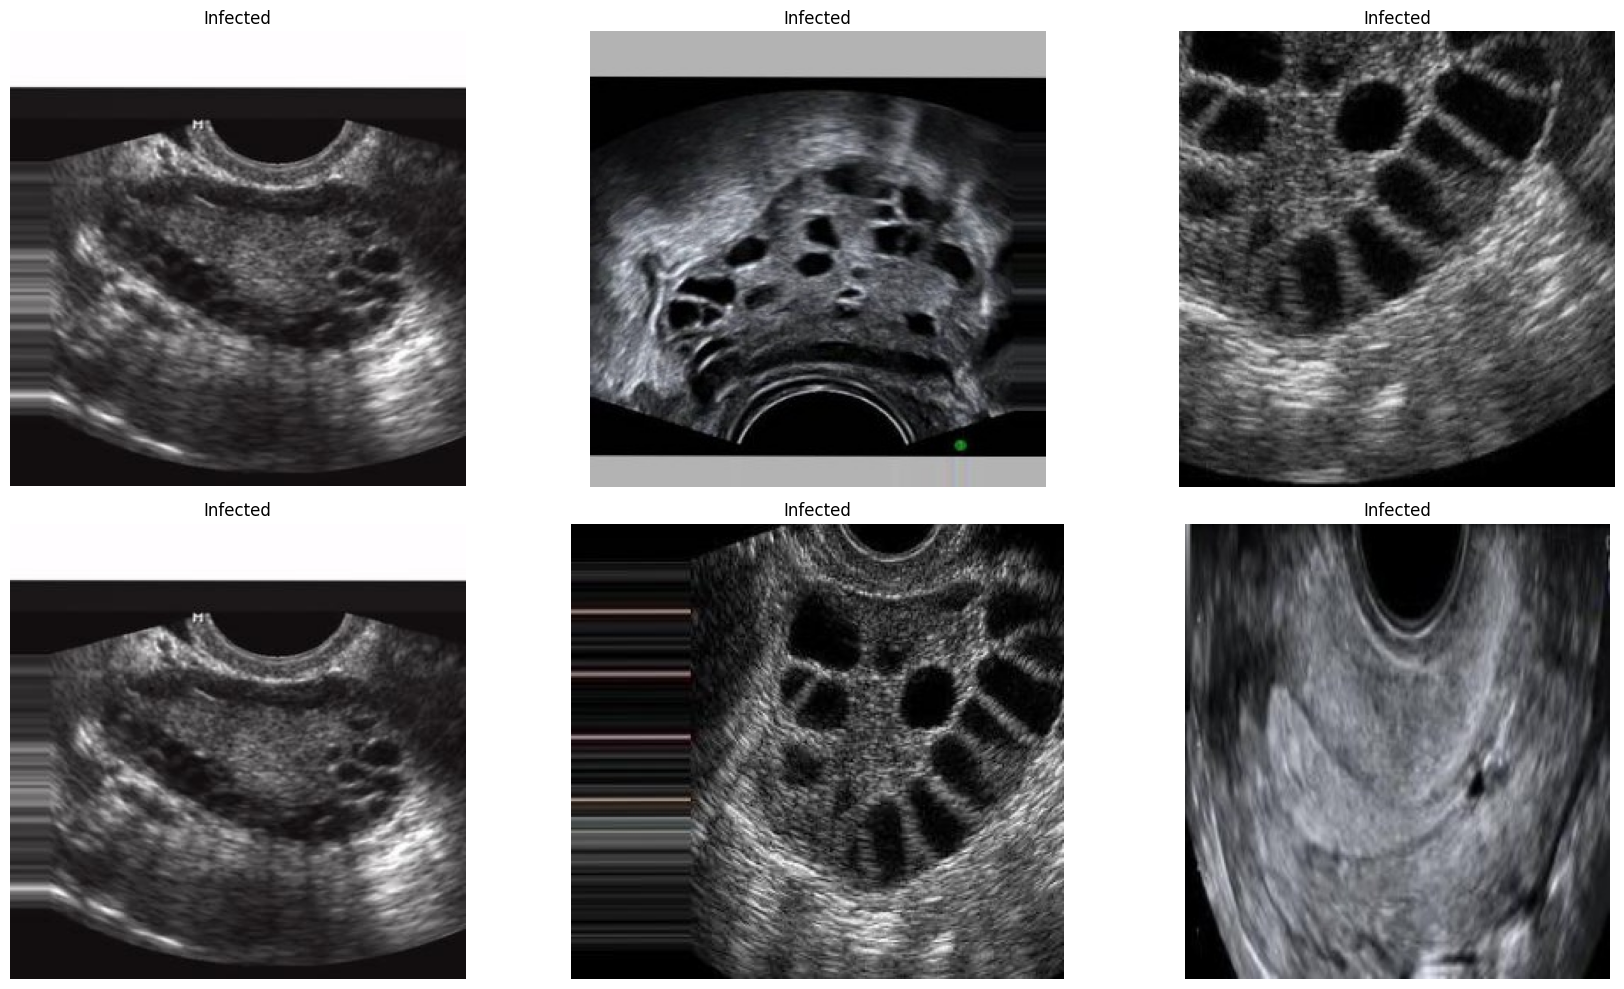

NONINFECTED SAMPLES


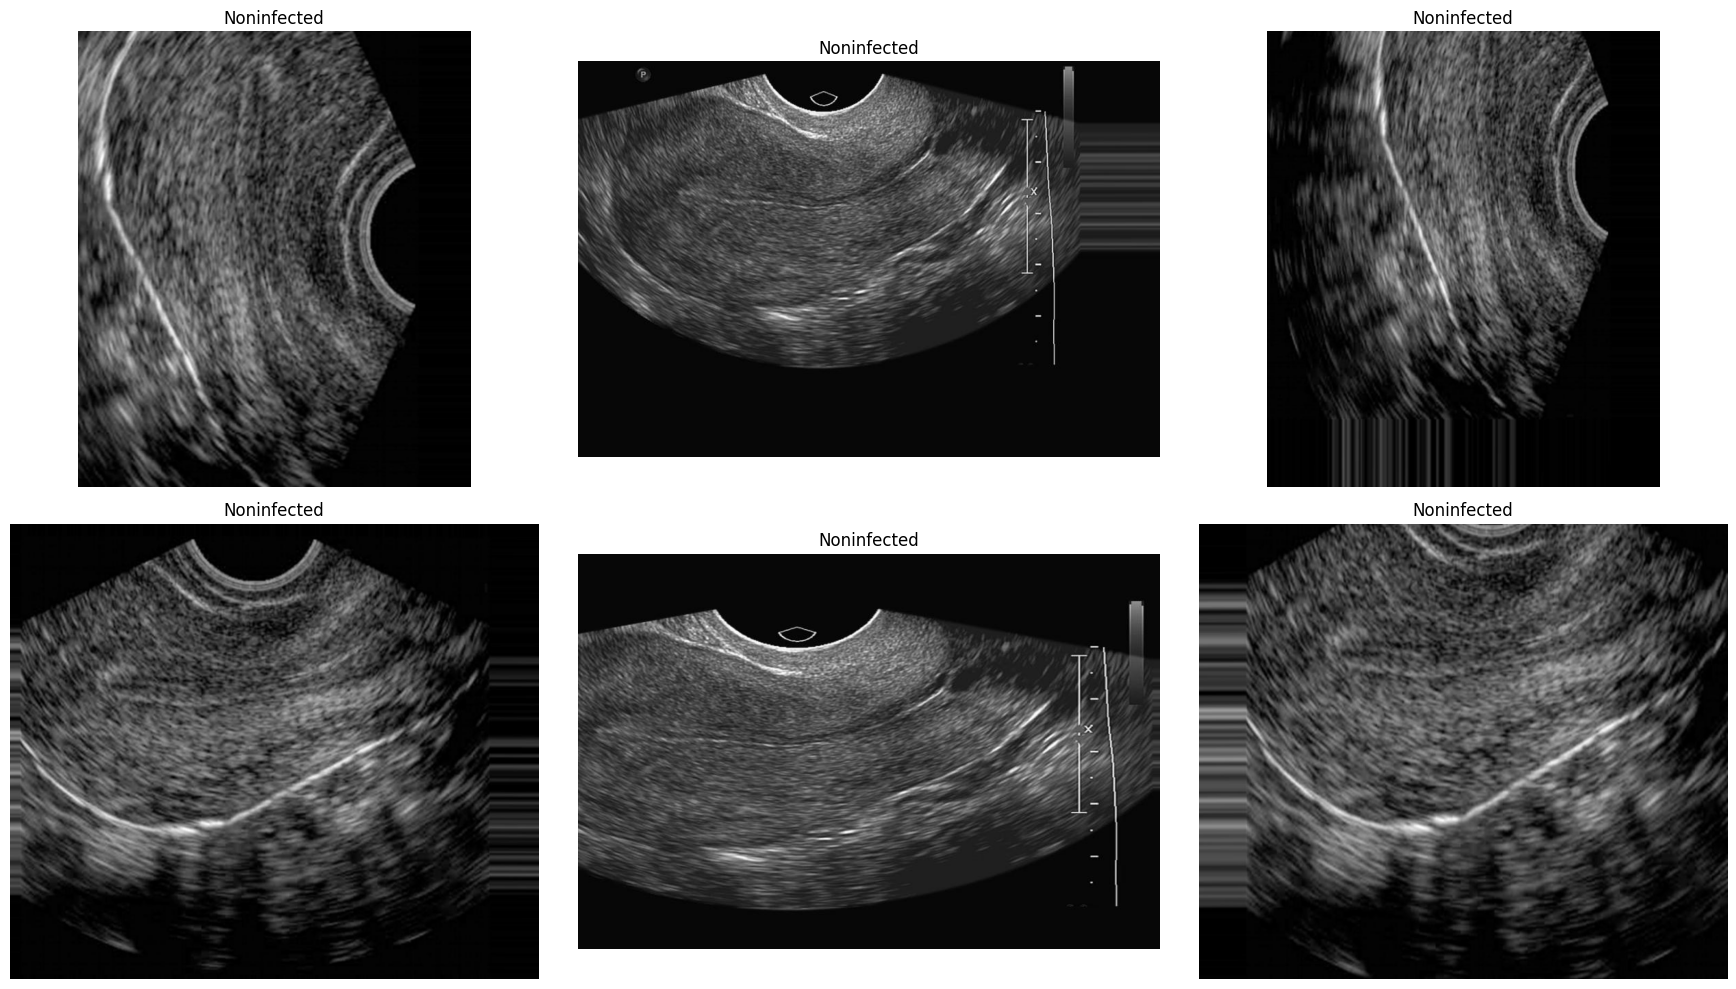

In [14]:
#Display Random Samples
import matplotlib.pyplot as plt
import random
from PIL import Image

def get_random_images(folder, n=6):

    valid_extensions = (
        '.jpg', '.jpeg', '.png',
        '.bmp', '.tif', '.tiff'
    )

    files = [
        file for file in os.listdir(folder)
        if file.lower().endswith(valid_extensions)
    ]

    return random.sample(files, min(n, len(files)))


def display_samples(folder, title, n=6):

    files = get_random_images(folder, n)

    plt.figure(figsize=(18, 10))

    for i, file in enumerate(files):

        path = os.path.join(folder, file)

        with Image.open(path) as img:
            image = img.copy()

        plt.subplot(2, 3, i + 1)
        plt.imshow(image)
        plt.title(title)
        plt.axis('off')

    plt.tight_layout()
    plt.show()


print("INFECTED SAMPLES")
display_samples(infected_path, "Infected", 6)

print("NONINFECTED SAMPLES")
display_samples(noninfected_path, "Noninfected", 6)

##Exact Duplicate Detection

In [15]:
#Calculate Exact Duplicate Groups
import hashlib
from collections import defaultdict

def get_image_hash(file_path):
    with open(file_path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()


# All dataset classes
all_folders = {
    "infected": infected_path,
    "noninfected": noninfected_path
}

hash_to_files = defaultdict(list)

valid_extensions = (
    '.jpg', '.jpeg', '.png',
    '.bmp', '.tif', '.tiff'
)

for class_name, folder_path in all_folders.items():

    for file in os.listdir(folder_path):

        if file.lower().endswith(valid_extensions):

            file_path = os.path.join(folder_path, file)

            try:
                # Verify that the file is a valid image
                with Image.open(file_path) as img:
                    img.verify()

                # Calculate file fingerprint
                image_hash = get_image_hash(file_path)

                hash_to_files[image_hash].append(
                    (class_name, file)
                )

            except Exception:
                pass


# Find duplicate groups
duplicates = {
    image_hash: files
    for image_hash, files in hash_to_files.items()
    if len(files) > 1
}


print("Total readable files:", sum(len(v) for v in hash_to_files.values()))
print("Unique image contents:", len(hash_to_files))
print("Duplicate groups:", len(duplicates))

Total readable files: 11784
Unique image contents: 3996
Duplicate groups: 1956


In [16]:
#See the duplicate-group sizes
from collections import Counter

group_sizes = Counter(
    len(files)
    for files in hash_to_files.values()
)

print("Duplicate group size distribution:")

for size, count in sorted(group_sizes.items()):
    print(f"{count} groups contain {size} identical files")

Duplicate group size distribution:
2040 groups contain 1 identical files
482 groups contain 2 identical files
12 groups contain 3 identical files
366 groups contain 4 identical files
1 groups contain 5 identical files
741 groups contain 6 identical files
3 groups contain 7 identical files
351 groups contain 8 identical files


In [17]:
#Check for duplicates across classes
cross_class_duplicates = []

for image_hash, files in hash_to_files.items():

    classes = set(
        class_name
        for class_name, filename in files
    )

    if len(classes) > 1:
        cross_class_duplicates.append(files)


print(
    "Duplicate groups appearing in BOTH classes:",
    len(cross_class_duplicates)
)


# Show first 10 examples if any exist

for i, files in enumerate(cross_class_duplicates[:10]):

    print(f"\nCross-class duplicate group {i + 1}")

    for class_name, filename in files:
        print(" ", class_name, "→", filename)

Duplicate groups appearing in BOTH classes: 0


##Unique Class Distribution

In [18]:
from collections import Counter

unique_class_counts = Counter()

for image_hash, files in hash_to_files.items():

    # Take the class of the first file.
    # We already verified that there are no
    # cross-class duplicate groups.

    class_name, filename = files[0]

    unique_class_counts[class_name] += 1


print("Unique image class distribution")
print("-" * 40)

print(
    "Infected:",
    unique_class_counts["infected"]
)

print(
    "Noninfected:",
    unique_class_counts["noninfected"]
)

total_unique = sum(unique_class_counts.values())

print(
    "Total unique:",
    total_unique
)

print("\nPercentages:")

print(
    f"Infected: "
    f"{unique_class_counts['infected'] / total_unique * 100:.2f}%"
)

print(
    f"Noninfected: "
    f"{unique_class_counts['noninfected'] / total_unique * 100:.2f}%"
)

Unique image class distribution
----------------------------------------
Infected: 3184
Noninfected: 812
Total unique: 3996

Percentages:
Infected: 79.68%
Noninfected: 20.32%


##Analyze Duplicate Rate by Class

In [19]:
# Calculate raw and unique image counts for each class

raw_counts = {
    "infected": len([
        f for f in os.listdir(infected_path)
        if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'))
    ]),
    "noninfected": len([
        f for f in os.listdir(noninfected_path)
        if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'))
    ])
}

unique_counts = {
    "infected": unique_class_counts["infected"],
    "noninfected": unique_class_counts["noninfected"]
}

print("Class-wise duplication analysis")
print("-" * 50)

for class_name in ["infected", "noninfected"]:

    raw = raw_counts[class_name]
    unique = unique_counts[class_name]

    duplicate_copies = raw - unique
    duplicate_percentage = (duplicate_copies / raw) * 100

    print(f"\n{class_name.capitalize()}")
    print(f"Raw images: {raw}")
    print(f"Unique images: {unique}")
    print(f"Duplicate copies: {duplicate_copies}")
    print(f"Duplicate percentage: {duplicate_percentage:.2f}%")

Class-wise duplication analysis
--------------------------------------------------

Infected
Raw images: 6784
Unique images: 3184
Duplicate copies: 3600
Duplicate percentage: 53.07%

Noninfected
Raw images: 5000
Unique images: 812
Duplicate copies: 4188
Duplicate percentage: 83.76%
